In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

In [9]:
from pathlib import Path


DATA_PATH = Path("..") / "data" / "raw" / "dataset_phishing.csv"

data = pd.read_csv(DATA_PATH)
data.head()

,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,...,0,1,0,45,-1,0,1,1,4,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,77,23,1,1,0,0,0,0,0,...,1,0,0,77,5767,0,0,1,2,phishing
2,https://support-appleld.com.secureupdate.duila...,126,50,1,4,1,0,1,2,0,...,1,0,0,14,4004,5828815,0,1,0,phishing
3,http://rgipt.ac.in,18,11,0,2,0,0,0,0,0,...,1,0,0,62,-1,107721,0,0,3,legitimate
4,http://www.iracing.com/tracks/gateway-motorspo...,55,15,0,2,2,0,0,0,0,...,0,1,0,224,8175,8725,0,0,6,legitimate


In [10]:
data.shape
data.info()
print(data.isnull().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 11430 entries, 0 to 11429
Data columns (total 89 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   url                         11430 non-null  str    
 1   length_url                  11430 non-null  int64  
 2   length_hostname             11430 non-null  int64  
 3   ip                          11430 non-null  int64  
 4   nb_dots                     11430 non-null  int64  
 5   nb_hyphens                  11430 non-null  int64  
 6   nb_at                       11430 non-null  int64  
 7   nb_qm                       11430 non-null  int64  
 8   nb_and                      11430 non-null  int64  
 9   nb_or                       11430 non-null  int64  
 10  nb_eq                       11430 non-null  int64  
 11  nb_underscore               11430 non-null  int64  
 12  nb_tilde                    11430 non-null  int64  
 13  nb_percent                  11430 non-null

 dữ liệu sạch,không có colunm nào bị null

[Text(0, 0, '5715'), Text(0, 0, '5715')]

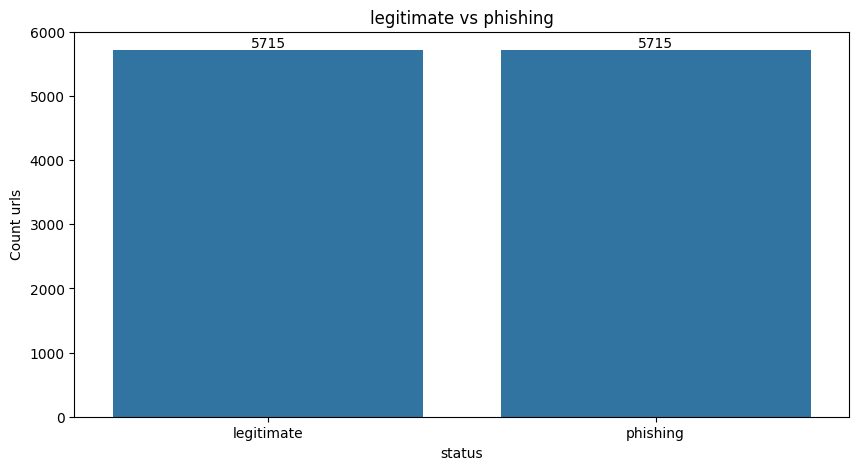

In [11]:
 #Kiểm tra xem count status là bao nhiêu
value_status=data["status"].value_counts()
plt.figure(figsize=(10,5))
ax=sns.barplot(x=value_status.index,y=value_status.values,)
plt.title("legitimate vs phishing")
plt.ylabel("Count urls")
ax.bar_label(ax.containers[0])

Ta nhận thấy tỉ lệ giữa số phishing và legitimate là rất cân bằng

In [12]:
#Kiểm tra xem có data nào bị trùng không
data.duplicated().sum()

np.int64(0)

In [13]:
print("\n" + "=" * 70)
print("6. PLACEHOLDER WHOIS (giá trị âm bất thường)")
print("=" * 70)
print(f"domain_age < 0        : {(data['domain_age'] < 0).sum()} dòng")
print(f"domain_registration_length < 0: {(data['domain_registration_length'] < 0).sum()} dòng")


6. PLACEHOLDER WHOIS (giá trị âm bất thường)
domain_age < 0        : 1837 dòng
domain_registration_length < 0: 46 dòng


In [14]:
#kiểm tra dữ liệu -1 có xuất hiện nhiều không và chiếm bao nhiêu phần trăm
minus_one_summary = pd.DataFrame({
    "count": (data == -1).sum(),
    "percentage": (data == -1).mean() * 100
})

minus_one_summary = minus_one_summary[
    minus_one_summary["count"] > 0
]

minus_one_summary.sort_values(
    "percentage",
    ascending=False
)

,count,percentage
domain_age,1781,15.581802
domain_registration_length,46,0.402450


ta thấy với col domain_age thì dữ liệu -1 chiểm 15% so với tổng số hàng là 11430,đây là điểm khá đáng chú ý
ta thử đâu sâu vào xem với những dữ liệu bị -1 của cột này thì status sẽ như nào

In [15]:
pd.crosstab(
    data["domain_age"] == -1,
    data["status"],
    normalize="index"
) * 100

status,legitimate,phishing
domain_age,,
False,50.730646,49.269354
True,46.041550,53.958450


ta thấy với data["domain_age]!=-1 thì hai lớp gần như cân bằng nhau
còn với ==-1 thì thấy nó có chênh lệch hơn nhưng không đáng kể
hiện tại mình cũng chưa kết luận nó có nên xóa những hàng dữ liệu này không

In [16]:
data[data["domain_age"] == -12]

,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
6514,http://fastfoodgozo.rs/a/yahoo/login.php,40,15,0,2,0,0,0,0,0,...,1,0,0,378,-12,0,0,1,0,phishing


In [17]:
# phân loại đặc trưng :nhị phân và liên tục 
num_cols = data.select_dtypes(include=[np.number]).columns.tolist()
binary_cols = [c for c in num_cols if set(data[c].dropna().unique()).issubset({0, 1})]
continuous_cols = [c for c in num_cols if c not in binary_cols]
print(binary_cols)
print(continuous_cols)

['ip', 'nb_or', 'nb_tilde', 'nb_star', 'nb_dslash', 'https_token', 'punycode', 'port', 'tld_in_path', 'tld_in_subdomain', 'abnormal_subdomain', 'prefix_suffix', 'random_domain', 'shortening_service', 'path_extension', 'nb_external_redirection', 'domain_in_brand', 'brand_in_subdomain', 'brand_in_path', 'suspecious_tld', 'ratio_nullHyperlinks', 'ratio_intRedirection', 'ratio_intErrors', 'login_form', 'external_favicon', 'submit_email', 'sfh', 'iframe', 'popup_window', 'onmouseover', 'right_clic', 'empty_title', 'domain_in_title', 'domain_with_copyright', 'whois_registered_domain', 'dns_record', 'google_index']
['length_url', 'length_hostname', 'nb_dots', 'nb_hyphens', 'nb_at', 'nb_qm', 'nb_and', 'nb_eq', 'nb_underscore', 'nb_percent', 'nb_slash', 'nb_colon', 'nb_comma', 'nb_semicolumn', 'nb_dollar', 'nb_space', 'nb_www', 'nb_com', 'http_in_path', 'ratio_digits_url', 'ratio_digits_host', 'nb_subdomains', 'nb_redirection', 'length_words_raw', 'char_repeat', 'shortest_words_raw', 'shortest_

In [18]:
# đánh dấu các feature có 1 value xuất hiện áp đáp,gần như k làm feature biến thiên
threshold= 0.99
rows=[]
for c in num_cols:
    top_freq = data[c].value_counts(normalize=True).iloc[0]
    if top_freq > threshold:
        rows.append((c, top_freq, data[c].mode()[0]))
nzv_df = pd.DataFrame(rows, columns=['feature', 'pct_top_value', 'top_value'])
nzv_df = nzv_df.sort_values('pct_top_value', ascending=False)
print(len(nzv_df))
nzv_df.head()

21


,feature,pct_top_value,top_value
0,nb_or,1.0,0
13,ratio_intRedirection,1.0,0
14,ratio_intErrors,1.0,0
15,submit_email,1.0,0
12,ratio_nullHyperlinks,1.0,0


Ta nhận thấy các feature trên có giá trị =0 áp đảo là 100%,vậy nên các feature này cũng sẽ không có ích trong việc dự đoán

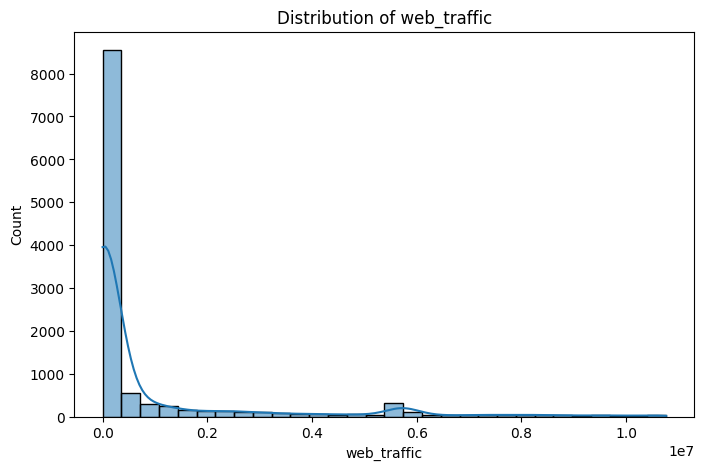

Skewness: 2.779269267807443


In [19]:
plt.figure(figsize=(8, 5))
sns.histplot(data["web_traffic"],bins=30,kde=True)
plt.title("Distribution of web_traffic")
plt.xlabel("web_traffic")
plt.ylabel("Count")
plt.show()

# Skewness
print("Skewness:", data["web_traffic"].skew())

In [20]:
 # Outlier (IQR) + skewness cho từng đặc trưng liên tục
factor=1.5
row = []
for c in continuous_cols:
    q1, q3 = data[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - factor * iqr, q3 + factor * iqr
    n_below = (data[c] < lower).sum()
    n_above = (data[c] > upper).sum()
    n_out = n_below + n_above
    skew_before = data[c].skew()
    skew_after_log = np.log1p(data[c]).skew() if data[c].min() >= 0 else np.nan
    rows.append((c, data[c].min(), data[c].max(), q1, q3, lower, upper,
                     n_below, n_above, n_out, n_out / len(data) * 100,
                     skew_before, skew_after_log))
cols = ['feature', 'min', 'max', 'q1', 'q3', 'lower_bound', 'upper_bound',
            'n_below', 'n_above', 'n_outliers', 'pct_outliers',
            'skew_before', 'skew_after_log']
out_df = pd.DataFrame(rows, columns=cols).sort_values('pct_outliers', ascending=False)
out_df.head(30)

,feature,min,max,q1,q3,lower_bound,upper_bound,n_below,n_above,n_outliers,pct_outliers,skew_before,skew_after_log
62,ratio_extErrors,0.0,1.000000e+00,0.00,0.034483,-0.051724,0.086207,0.0,2149.0,2149.0,18.801400,3.510798,3.017057
69,web_traffic,0.0,1.076799e+07,0.00,373845.500000,-560768.250000,934613.750000,0.0,2138.0,2138.0,18.705162,2.779269,0.093172
55,phish_hints,0.0,1.000000e+01,0.00,0.000000,0.000000,0.000000,0.0,2041.0,2041.0,17.856518,3.216484,2.220752
65,ratio_extMedia,0.0,1.000000e+02,0.00,33.333333,-50.000000,83.333333,0.0,2012.0,2012.0,17.602800,1.265615,0.826390
29,nb_underscore,0.0,1.800000e+01,0.00,0.000000,0.000000,0.000000,0.0,1695.0,1695.0,14.829396,7.265925,2.779738
28,nb_eq,0.0,1.900000e+01,0.00,0.000000,0.000000,0.000000,0.0,1564.0,1564.0,13.683290,6.530036,2.916154
26,nb_qm,0.0,3.000000e+00,0.00,0.000000,0.000000,0.000000,0.0,1555.0,1555.0,13.604549,2.488737,2.218509
67,domain_registration_length,-1.0,2.982900e+04,84.00,449.000000,-463.500000,996.500000,0.0,1529.0,1529.0,13.377078,9.819607,NaN
41,ratio_digits_host,0.0,8.000000e-01,0.00,0.000000,0.000000,0.000000,0.0,1503.0,1503.0,13.149606,5.591198,4.872880
46,shortest_words_raw,1.0,3.100000e+01,2.00,3.000000,0.500000,4.500000,0.0,1435.0,1435.0,12.554681,3.156658,0.887196


dựa vào đây ta thấy có rất nhiều feature có outlier chiếm giá trị lớn
sử dụng log1p thì thấy skew có giảm với nhiều feature,giúp phân bố cân bằng hơn

c:\Users\LOQ\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\LOQ\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]



5. TƯƠNG QUAN VỚI NHÃN (top 20)
google_index           0.731171
page_rank             -0.511137
nb_www                -0.443468
ratio_digits_url       0.356395
domain_in_title        0.342807
nb_hyperlinks         -0.342628
phish_hints            0.335393
domain_age            -0.331889
ip                     0.321698
nb_qm                  0.294319
length_url             0.248580
ratio_intHyperlinks   -0.243982
nb_slash               0.242270
length_hostname        0.238322
nb_eq                  0.233386
ratio_digits_host      0.224335
shortest_word_host     0.223084
prefix_suffix          0.214681
longest_word_path      0.212709
tld_in_subdomain       0.208884


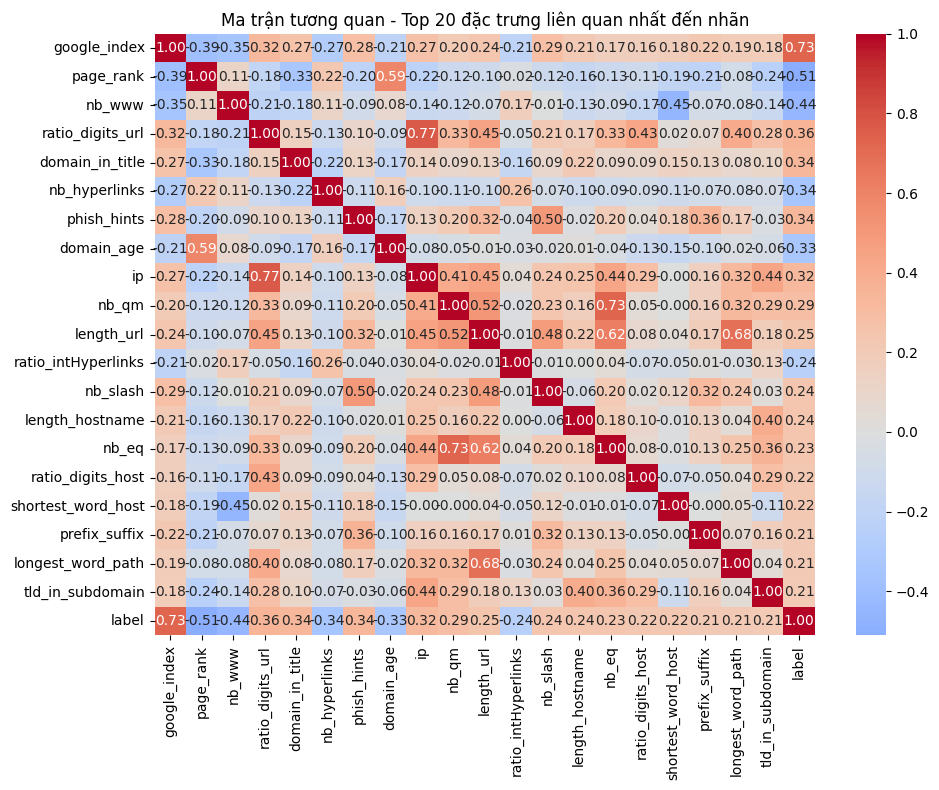

In [21]:
# Tương quan với nhãn và tương quan đa cộng tuyến
df = data.copy()
df['label'] = (df['status'] == 'phishing').astype(int)
 
corr_target = df[num_cols].corrwith(df['label']).drop('label', errors='ignore')
corr_target = corr_target.sort_values(key=abs, ascending=False)
top_fit=corr_target.head(20).index.to_list()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(df[top_fit + ['label']].corr(), annot=True, fmt='.2f',cmap='coolwarm', center=0, ax=ax)
ax.set_title('Ma trận tương quan - Top 20 đặc trưng liên quan nhất đến nhãn')
plt.tight_layout()
print("\n" + "=" * 70)
print("5. TƯƠNG QUAN VỚI NHÃN (top 20)")
print("=" * 70)
print(corr_target.head(20).to_string())


In [22]:
high_threshold=0.9
corr_matrix = df[num_cols].corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
pairs = upper_tri.stack().sort_values(ascending=False)
high_pairs = pairs[pairs > high_threshold]
high_pairs.head(5)

longest_words_raw  longest_word_path    0.968503
nb_and             nb_eq                0.906404
dtype: float64

nhận  thấy feature google_index  có tương quan khá mạnh với nhãn
tiếp theo đó là các cặp feature như (longest_words_raw,longest_word_path),(nb_and,nb_eq) tương quan quan mạnh
vậy chúng ta cần loại bỏ 1 trong 2 feature của mỗi cặp

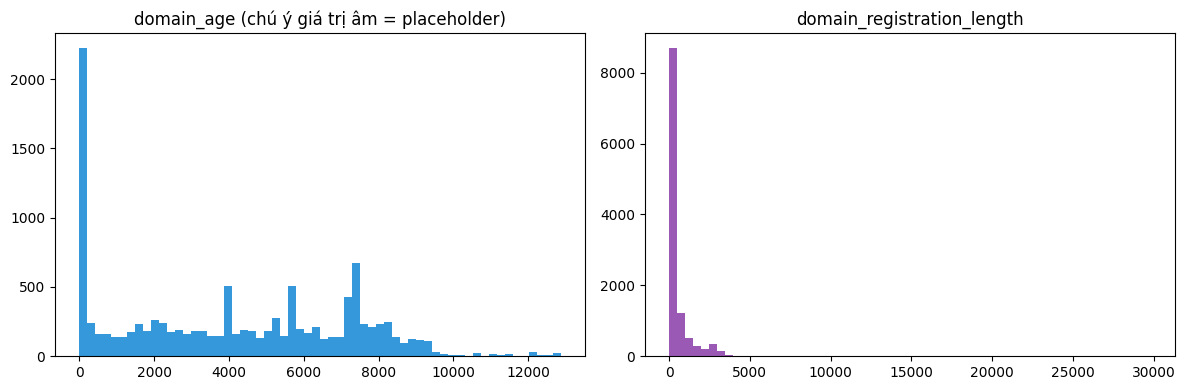

In [23]:
# domain_age / domain_registration_length
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['domain_age'], bins=60, color='#3498db')
axes[0].set_title('domain_age (chú ý giá trị âm = placeholder)')
axes[1].hist(df['domain_registration_length'], bins=60, color='#9b59b6')
axes[1].set_title('domain_registration_length')
plt.tight_layout()

## . Tiền xử lý

Thứ tự (để **tránh rò rỉ dữ liệu** — mọi thống kê như trung vị, ngưỡng skew, mean/std đều chỉ tính trên tập **train**):

1. Mã hóa nhãn, bỏ cột `url`
2. Chia train/test (80/20, stratify)
3. Xử lý placeholder WHOIS (cờ `*_unknown` + điền trung vị)
4. Loại đặc trưng near-zero-variance
5. Loại đặc trưng đa cộng tuyến
6. `log1p` cho các đặc trưng đếm lệch mạnh
7. `StandardScaler` cho đặc trưng liên tục (**không** scale đặc trưng nhị phân 0/1)

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [25]:


data1 = data.drop(columns=['url']).copy()          # url đã được trích thành 87 đặc trưng, không đưa vào mô hình
data1['label'] = (data['status'] == 'phishing').astype(int) 
data1 = data1.drop(columns=['status'])

X = data1.drop(columns=['label'])
y = data1['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
X_train_raw=X_train.copy()
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Tỉ lệ phishing - train:', y_train.mean().round(3), '| test:', y_test.mean().round(3))



Train: (9144, 87) | Test: (2286, 87)
Tỉ lệ phishing - train: 0.5 | test: 0.5


Loại đặc trưng near-zero-variance

In [26]:
NZV_THRESHOLD = 0.99
nzv_cols = [c for c in X_train.columns
            if X_train[c].value_counts(normalize=True).iloc[0] > NZV_THRESHOLD]
X_train = X_train.drop(columns=nzv_cols)
X_test = X_test.drop(columns=nzv_cols)
print(f'Đã loại {len(nzv_cols)} đặc trưng near-zero-variance:')
print(nzv_cols)

Đã loại 21 đặc trưng near-zero-variance:
['nb_or', 'nb_tilde', 'nb_star', 'nb_comma', 'nb_dollar', 'nb_dslash', 'punycode', 'port', 'path_extension', 'nb_external_redirection', 'brand_in_subdomain', 'brand_in_path', 'ratio_nullHyperlinks', 'ratio_intRedirection', 'ratio_intErrors', 'submit_email', 'sfh', 'iframe', 'popup_window', 'onmouseover', 'right_clic']


Loại đặc trưng đa cộng tuyến

In [27]:
CORR_THRESHOLD = 0.95
corr_abs = X_train.corr().abs()
target_corr = X_train.corrwith(y_train).abs()
upper_tri = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
pairs = upper_tri.stack().sort_values(ascending=False)

high_corr_drop = set()
for (a, b), val in pairs[pairs > CORR_THRESHOLD].items():
    if a in high_corr_drop or b in high_corr_drop:
        continue
    # giữ cột có tương quan với nhãn mạnh hơn, bỏ cột còn lại
    drop = a if target_corr[a] < target_corr[b] else b
    high_corr_drop.add(drop)
    print(f'{a} ~ {b} (|corr|={val:.2f}) -> loại {drop}')

X_train = X_train.drop(columns=list(high_corr_drop))
X_test = X_test.drop(columns=list(high_corr_drop))
print('Số đặc trưng còn lại:', X_train.shape[1])

longest_words_raw ~ longest_word_path (|corr|=0.97) -> loại longest_words_raw
Số đặc trưng còn lại: 65


In [28]:
SKEW_THRESHOLD = 1.5
binary_cols_final = [c for c in X_train.columns if set(X_train[c].unique()).issubset({0, 1})]
continuous_cols_final = [c for c in X_train.columns if c not in binary_cols_final]

skewed_cols = [c for c in continuous_cols_final
               if X_train[c].min() >= 0 and X_train[c].skew() > SKEW_THRESHOLD]

X_train_before_log = X_train.copy()
for c in skewed_cols:
    X_train[c] = np.log1p(X_train[c])
    X_test[c] = np.log1p(X_test[c].clip(lower=0))

print(f'Nhị phân: {len(binary_cols_final)} | Liên tục: {len(continuous_cols_final)}')
print(f'Đã log1p cho {len(skewed_cols)} đặc trưng (skew > {SKEW_THRESHOLD}):')
print(skewed_cols)

Nhị phân: 18 | Liên tục: 47
Đã log1p cho 36 đặc trưng (skew > 1.5):
['length_url', 'length_hostname', 'nb_dots', 'nb_hyphens', 'nb_at', 'nb_qm', 'nb_and', 'nb_eq', 'nb_underscore', 'nb_percent', 'nb_slash', 'nb_colon', 'nb_semicolumn', 'nb_space', 'nb_com', 'http_in_path', 'ratio_digits_url', 'ratio_digits_host', 'nb_redirection', 'length_words_raw', 'char_repeat', 'shortest_words_raw', 'shortest_word_host', 'shortest_word_path', 'longest_word_host', 'longest_word_path', 'avg_words_raw', 'avg_word_host', 'avg_word_path', 'phish_hints', 'statistical_report', 'nb_hyperlinks', 'nb_extCSS', 'ratio_extRedirection', 'ratio_extErrors', 'web_traffic']


In [29]:
skew_cmp = pd.DataFrame({'skew_truoc': X_train_before_log[skewed_cols].skew(),
                         'skew_sau': X_train[skewed_cols].skew()}).sort_values('skew_truoc', ascending=False)
display(skew_cmp)

,skew_truoc,skew_sau
nb_space,28.574072,10.324966
nb_extCSS,24.030286,1.891638
nb_percent,22.318942,7.819582
nb_semicolumn,16.699704,8.582533
http_in_path,14.722634,10.163846
char_repeat,14.638151,-0.054210
longest_word_path,13.210021,-0.177162
avg_word_path,12.714639,-0.425628
nb_colon,11.427309,9.031172
nb_and,10.090766,4.446739


In [30]:
scaler = StandardScaler()
X_train[continuous_cols_final] = scaler.fit_transform(X_train[continuous_cols_final])
X_test[continuous_cols_final] = scaler.transform(X_test[continuous_cols_final])
print('Đã scale', len(continuous_cols_final), 'đặc trưng liên tục; giữ nguyên', len(binary_cols_final), 'đặc trưng nhị phân.')

Đã scale 47 đặc trưng liên tục; giữ nguyên 18 đặc trưng nhị phân.


In [31]:
print(binary_cols_final)

['ip', 'https_token', 'tld_in_path', 'tld_in_subdomain', 'abnormal_subdomain', 'prefix_suffix', 'random_domain', 'shortening_service', 'domain_in_brand', 'suspecious_tld', 'login_form', 'external_favicon', 'empty_title', 'domain_in_title', 'domain_with_copyright', 'whois_registered_domain', 'dns_record', 'google_index']


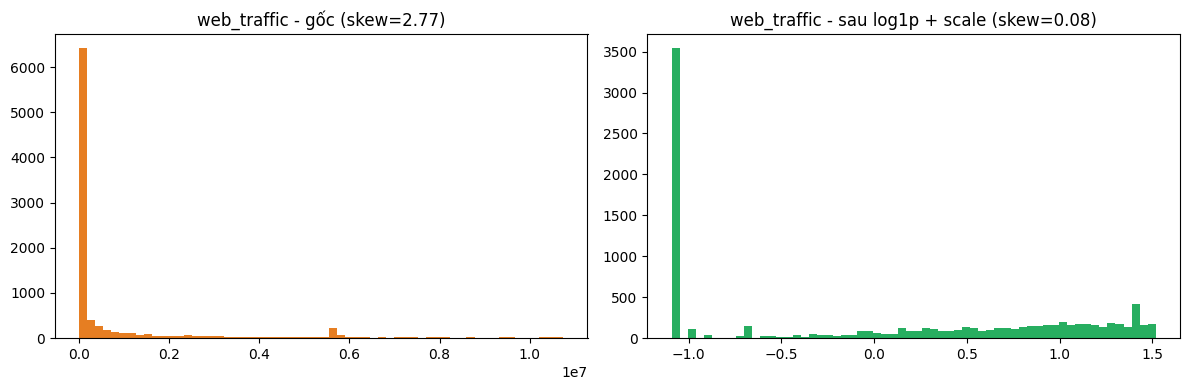

In [32]:
# web_traffic: trước và sau xử lý
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(X_train_raw['web_traffic'], bins=60, color='#e67e22')
axes[0].set_title(f"web_traffic - gốc (skew={X_train_raw['web_traffic'].skew():.2f})")
axes[1].hist(X_train['web_traffic'], bins=60, color='#27ae60')
axes[1].set_title(f"web_traffic - sau log1p + scale (skew={X_train['web_traffic'].skew():.2f})")
plt.tight_layout()
plt.show()

In [33]:
import joblib


import joblib
from pathlib import Path

# Thư mục gốc của project
PROJECT_DIR = Path("..")

# Thư mục lưu dữ liệu đã xử lý
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Lưu train và test
train_out = X_train.assign(label=y_train.values)
test_out = X_test.assign(label=y_test.values)

train_out.to_csv(PROCESSED_DIR / "train_processed.csv", index=False)
test_out.to_csv(PROCESSED_DIR / "test_processed.csv", index=False)

# Lưu các thông tin phục vụ preprocessing
joblib.dump(
    {
        "scaler": scaler,
        "continuous_cols": continuous_cols_final,
        "skewed_cols": skewed_cols,
        "dropped_nzv": nzv_cols,
        "dropped_corr": list(high_corr_drop),
    },
 PROCESSED_DIR / "preprocessing_artifacts.joblib",
)

print("Đã lưu các file vào:", PROCESSED_DIR.resolve())
print(" - train_processed.csv")
print(" - test_processed.csv")
print(" - preprocessing_artifacts.joblib")

Đã lưu các file vào: C:\pro_github\final-project-template\project\data\processed
 - train_processed.csv
 - test_processed.csv
 - preprocessing_artifacts.joblib


In [34]:
import os

print(os.getcwd())

c:\pro_github\final-project-template\project\notebook
